# WEEK 4
# Project Title    : Data-Driven Inventory Management And Demand Forecasting
# Approach        : Machine Learning, Demand Forecasting, Predictive Modeling, Inventory Optimization
# Technology     : Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn
# Report Type   : Predictive Modeling and Optimization in Logistics Systems



# BY:
#   V.THANIGAI MURUGAN
#   B.TECH CSE

# A. Loading libraries:

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# B. Exploratory Data Analysis (EDA):

In [3]:
np.random.seed(42); n = 800
df = pd.DataFrame({"distance_km": np.random.gamma(2.5,90,n).clip(10,900),"weight_kg": np.random.lognormal(4.2,.65,n).clip(2,1500),
 		               "order_units": np.random.poisson(35,n).clip(1,120),"traffic_index": np.random.uniform(.1,1,n),
                   "weather_risk": np.random.uniform(0,1,n),"warehouse_hours": np.random.gamma(2,1.2,n).clip(.2,12),
 		               "route_type": np.random.choice(["Urban","Highway","Mixed"],n)})
route_effect = df.route_type.map({"Urban":2.5,"Highway":-.5,"Mixed":1.0})
df["delivery_hours"] = (3 + .035*df.distance_km + 4.5*df.traffic_index+ 3.2*df.weather_risk + .55*df.warehouse_hours + route_effect
                        + np.random.normal(0,4,n)).clip(2,None)
df.loc[np.random.choice(df.index,12,replace=False),"weight_kg"] = np.nan

# C. Demonstrate missing-value checks and cleaning:

In [4]:
features = ["distance_km","weight_kg","order_units","traffic_index","weather_risk","warehouse_hours","route_type"]
target = "delivery_hours"
X, y = df[features], df[target]
numeric =["distance_km","weight_kg","order_units","traffic_index","weather_risk","warehouse_hours"]
categorical = ["route_type"]
preprocess = ColumnTransformer([("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),numeric),
             ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("encode",OneHotEncoder(handle_unknown="ignore"))]),categorical)])
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.20,random_state=42)
models = {"Linear Regression":LinearRegression(),"RandomForest":RandomForestRegressor(n_estimators=250,min_samples_leaf=3,random_state=42,n_jobs=-1)}
pipes, rows = {}, []
for name, estimator in models.items():
    pipe = Pipeline([("preprocess",preprocess),("model",estimator)])
    pipe.fit(X_train,y_train)
    pred = pipe.predict(X_test)
    pipes[name] = pipe
    rows.append({"Model":name,"MAE_hours":mean_absolute_error(y_test,pred),"RMSE_hours":np.sqrt(mean_squared_error(y_test,pred)),
                 "R2":r2_score(y_test,pred)})
metrics = pd.DataFrame(rows).sort_values("RMSE_hours")
print(metrics.round(3))
best_name = metrics.iloc[0]["Model"]; best = pipes[best_name]
pred = best.predict(X_test)

               Model  MAE_hours  RMSE_hours     R2
0  Linear Regression      3.335       4.209  0.484
1       RandomForest      3.613       4.576  0.390


# D. Data Visualization:

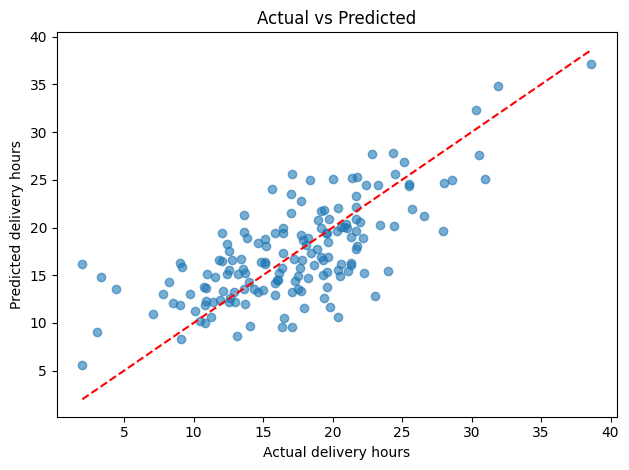

In [6]:
plt.scatter(y_test,pred,alpha=.6)
lims=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())]
plt.plot(lims,lims,"r--"); plt.xlabel("Actual delivery hours")
plt.ylabel("Predicted delivery hours"); plt.title("Actual vs Predicted")
plt.tight_layout();
plt.show()

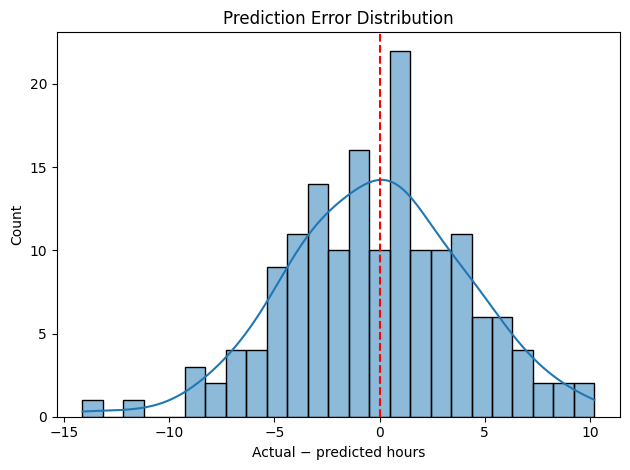

In [7]:
residuals = y_test - pred
sns.histplot(residuals,kde=True,bins=25)
plt.axvline(0,color="red",linestyle="--")
plt.title("Prediction Error Distribution"); plt.xlabel("Actual − predicted hours")
plt.tight_layout();
plt.show()

In [8]:
scenario = X_test.copy()
scenario["traffic_index"] = (scenario["traffic_index"]-.10).clip(0,1)
print("Mean predicted hours saved under simulated scenario:",round(float(np.mean(best.predict(X_test)-best.predict(scenario))),2))

Mean predicted hours saved under simulated scenario: 0.53
